# Cải thiện đánh giá phát âm · 24/10/2026

So sánh **năm checkpoint trên cùng 120 audio có nhãn chuyên gia**, thêm ba audio phát triển không chấm điểm. Thử riêng hai chính sách quyết định của wav2vec2 B với ngưỡng chọn trên validation và khóa trước test.

Notebook này chỉ đọc kết quả đã lưu và tạo biểu đồ/báo cáo. **Không tải model, không inference, không train và không đổi demo.** Điểm nhãn gốc, Full39 và Common37 là ba panel riêng; không dùng điểm gộp âm để thay kết quả task gốc.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/report_pronunciation_improvement.py").is_file())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
from scripts import report_pronunciation_improvement as report
from IPython.display import display, Image, HTML
import pandas as pd
OUT = ROOT / "data/generated/pronunciation-improvement-20261024"
print("Workspace:", ROOT)
print("Kết quả:", OUT)

Workspace: D:\NCC\MDD
Kết quả: D:\NCC\MDD\data\generated\pronunciation-improvement-20261024


## 1. Kiểm tra dữ liệu và tạo báo cáo từ JSON

Chỉ tiếp tục khi cả năm model hoàn tất, cùng đúng 120 audio chuyên gia và ba audio phát triển; ba baseline cũ phải giữ nguyên. Báo cáo kiểm tra hash của plan/ngưỡng policy, đối chiếu các bảng đếm và không thay đổi ngưỡng.

In [2]:
bundle = report.build(OUT)
print("Đủ năm model:", ", ".join(report.NAMES[m] for m in report.MODELS))
print("Expert cases:", sum(c["group"] == "expert_test" for c in bundle["manifest"]["cases"]))
print("Nguồn đầu vào:")
display(pd.DataFrame([{"file": k, "sha256": v} for k, v in bundle["input_sha256"].items()]))

Report: D:\NCC\MDD\data\generated\pronunciation-improvement-20261024\report.html
Đủ năm model: wav2vec2 B · local, XLS-R 300M · TIMIT, CROTTC-IF, Charsiu · CTC, Charsiu · FC 10 ms
Expert cases: 120
Nguồn đầu vào:


,file,sha256
0,charsiu/manifest.json,f9b2f99ce1d42af3476457963e8a09054c9cc99d180747...
1,charsiu/results.json,4a2578bd8b180a99d5dda99822c2ecabfee57a708ac430...
2,../model-comparison-20261024/pronunciation/man...,dd9634f72d6c72fcd9e0597b52b6127e9953c514adfeef...
3,../model-comparison-20261024/pronunciation/res...,124d1a6a5244461e919710384f51b5f6dfba99eaa6b1b6...
4,policies/results.json,62a11985ba0d62ae6bc4a293e5e6c265472b9566a8bc99...
5,policies/plan.json,949ffdaacde4316cb338df3e080a6ac537ad5f380bba42...
6,policies/locked_policy.json,e319022d651a1d6625ea10c5d658d567c84ae16d66770d...
7,policies/test_cache_identity.json,88a7456d323a8a1afe4c923a48f4a67922151b0619ca4b...
8,policies/validation_features.jsonl,fb1eef2378beb586c3b98cfc2de7b861ebc3afb9152a99...
9,policies/test_features.jsonl,f6e8d041a11840c60aa461c740a6065b72aeefd370f657...


## 2. Nhận dạng âm và phát hiện lỗi

F1 cao hơn tốt hơn; PER thấp hơn tốt hơn. Micro metrics được tính lại từ bảng đếm, không lấy trung bình F1 từng câu. Nhãn chuyên gia gốc là panel chính; Full39 và Common37 được trình bày riêng vì normalization làm thay đổi các phân biệt âm.

,inventory,model,cases,f1,per,precision,recall,removed_expert_events,mean_inference_sec,devices
0,research_original_inventory,cascade-B,120,0.490658,0.167787,0.486312,0.495082,0,0.076433,cuda:0
1,research_full39,cascade-B,120,0.490164,0.163555,0.490164,0.490164,0,0.076433,cuda:0
2,research_common37,cascade-B,120,0.492077,0.161314,0.488411,0.495798,15,0.076433,cuda:0
3,research_original_inventory,timit-xlsr-300m,120,0.406250,0.269604,0.320683,0.554098,0,0.098017,cuda:0
4,research_full39,timit-xlsr-300m,120,0.406250,0.265870,0.320683,0.554098,0,0.098017,cuda:0
5,research_common37,timit-xlsr-300m,120,0.417402,0.247697,0.334006,0.556303,15,0.098017,cuda:0
6,research_original_inventory,crottc-if,120,0.196680,0.466517,0.131667,0.388525,0,3.311592,cuda:0
7,research_full39,crottc-if,120,0.196680,0.462036,0.131667,0.388525,0,3.311592,cuda:0
8,research_common37,crottc-if,120,0.196817,0.459547,0.131065,0.394958,15,3.311592,cuda:0
9,research_original_inventory,charsiu-ctc,120,0.295374,0.208364,0.322957,0.272131,0,0.057842,cuda:0


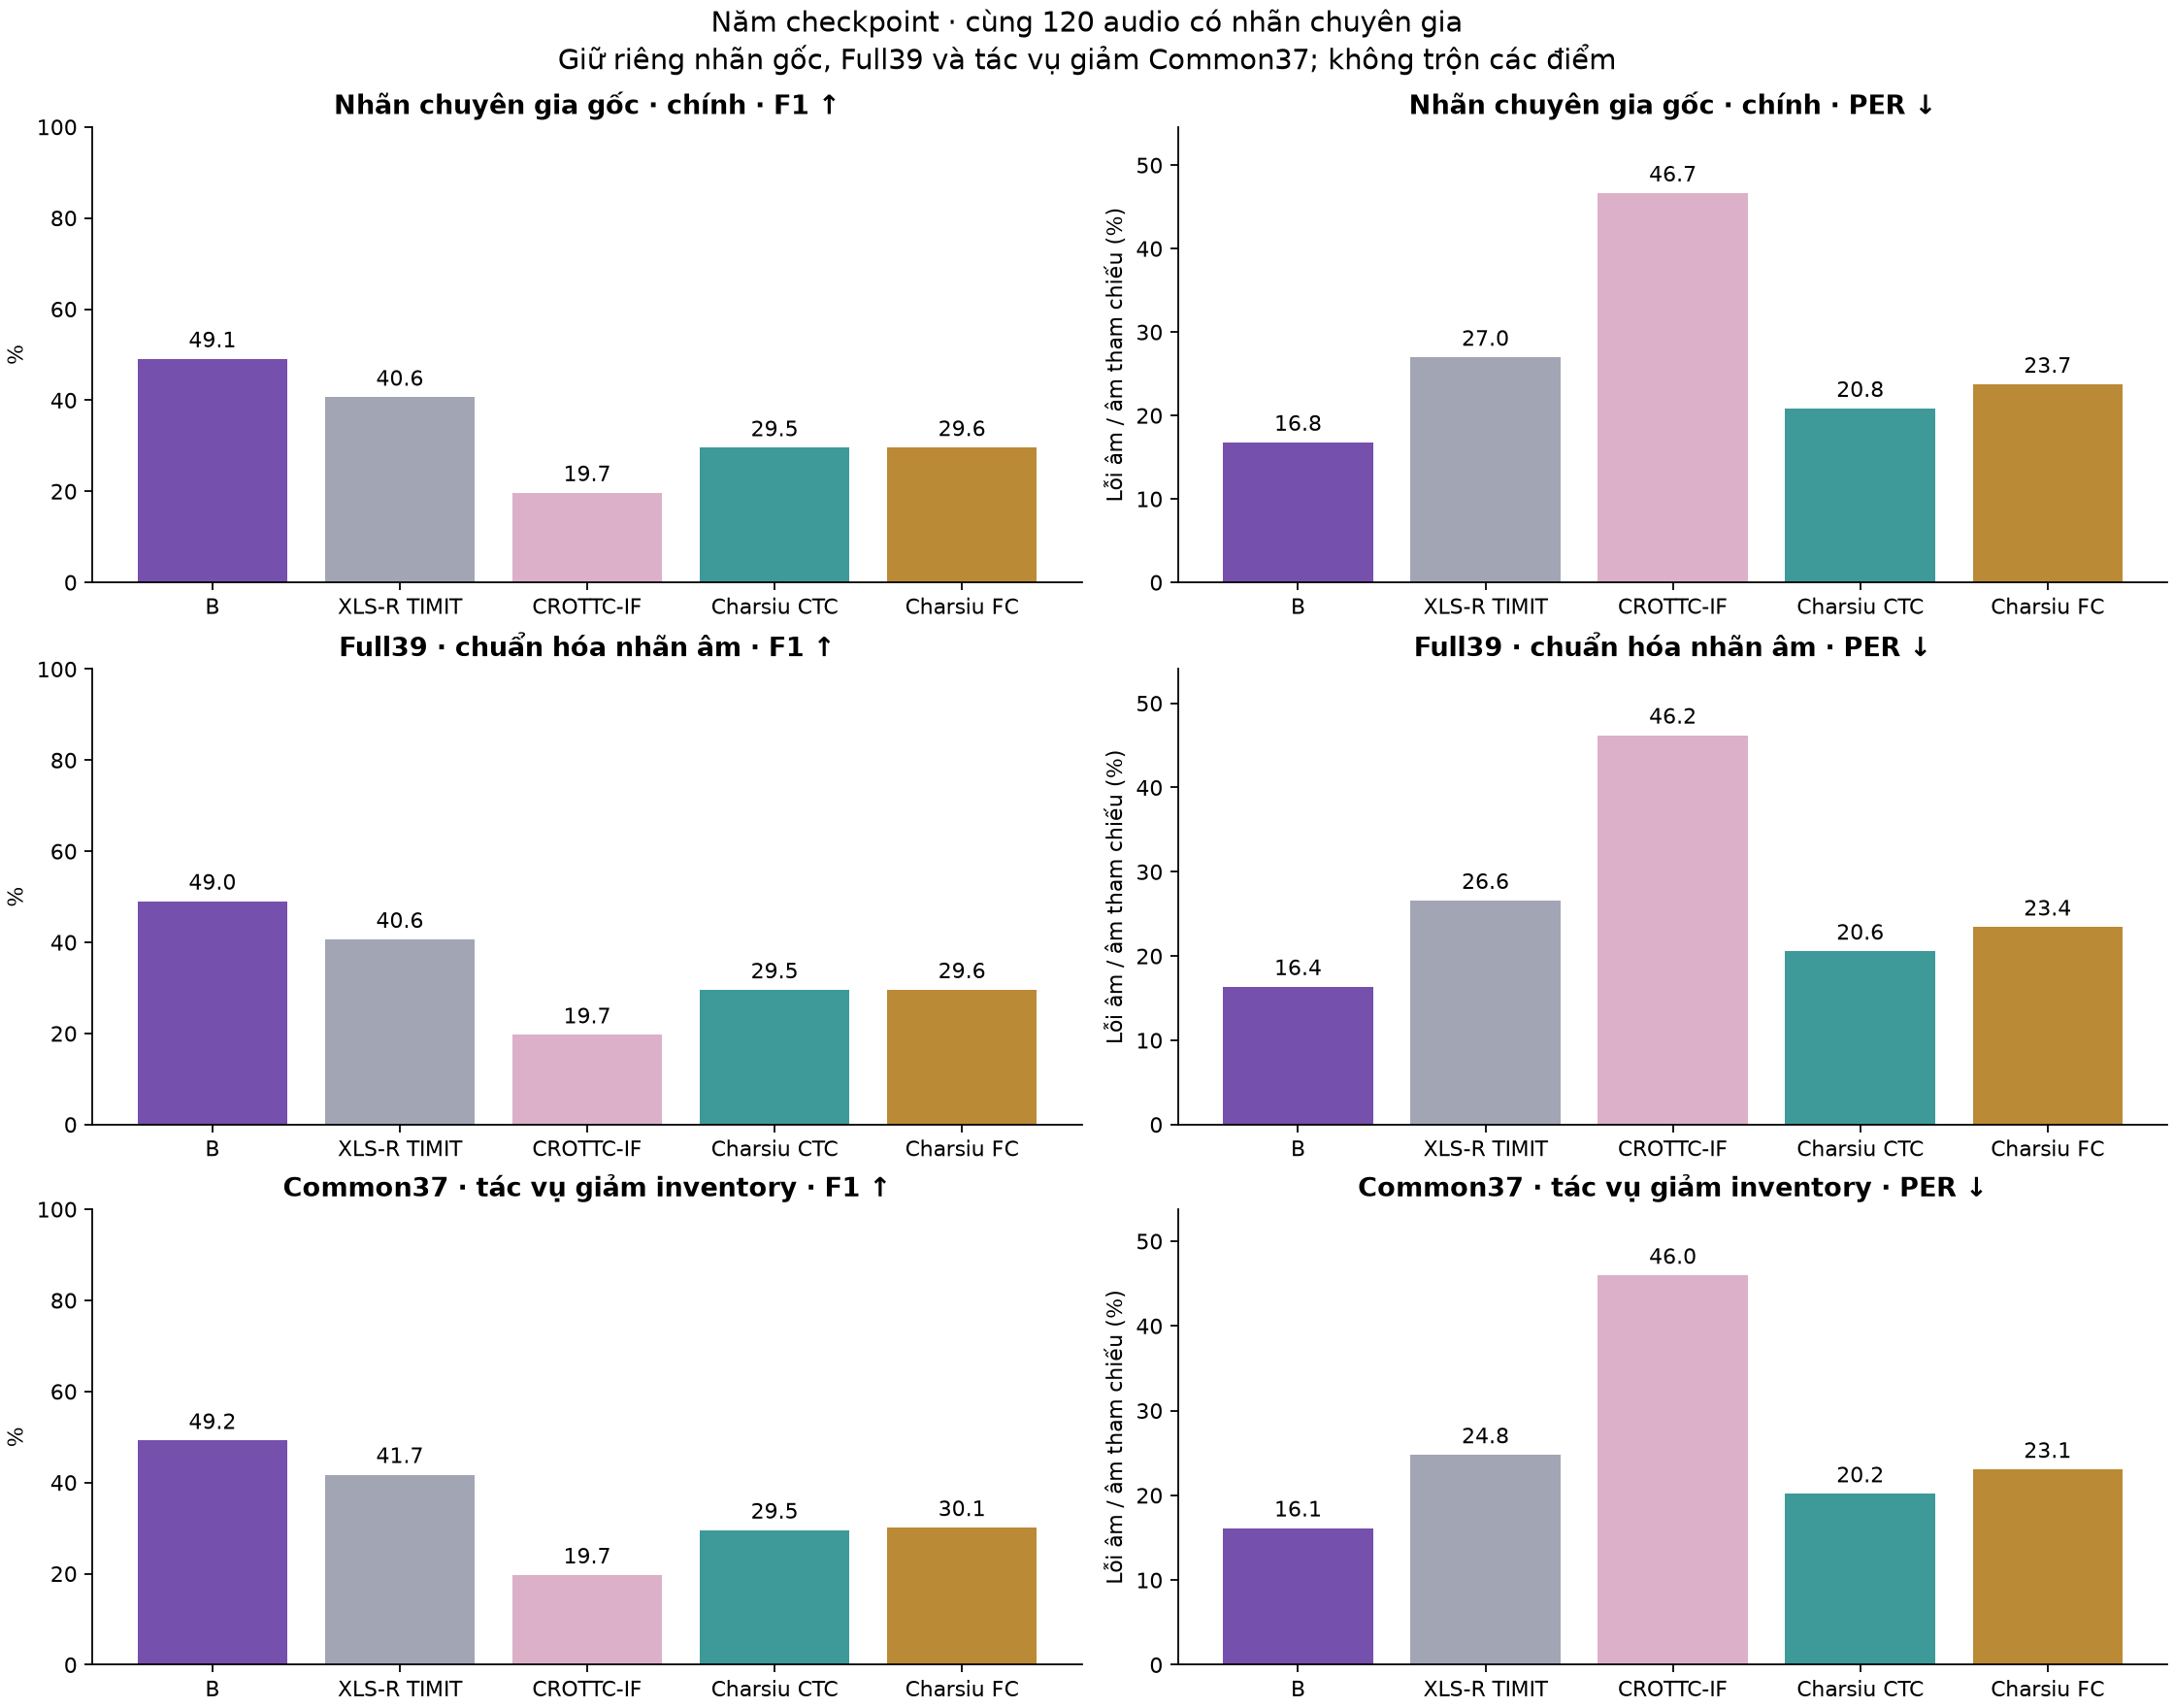

In [3]:
models = pd.DataFrame(report.model_rows(bundle))
display(models[["inventory", "model", "cases", "f1", "per", "precision", "recall", "removed_expert_events", "mean_inference_sec", "devices"]])
display(Image(filename=str(OUT / "model_matrix.png")))

## 3. Báo nhầm, bỏ sót và coverage

Gợi ý từ dùng cùng dictionary-variant reviewer cho năm model, chưa phải chẩn đoán đã calibration. Recall toàn bộ vẫn tính cả các lỗi bị abstain; FPR trên mọi từ đúng được đặt cạnh FPR trên phần có quyết định. Từ có lỗi chỉ dùng word_index chuyên gia hợp lệ; không trộn với word metrics suy từ canonical positions.

,model,review_reference_words,review_gold_error_words,review_available_words,review_false_positive_all_correct,review_false_positive_rate_decided,review_recall_all_errors,review_recall_available_only,review_coverage
1,cascade-B,1165,461,1165,0.214489,0.214489,0.566161,0.566161,1.000000
4,timit-xlsr-300m,1165,461,1165,0.406250,0.406250,0.722343,0.722343,1.000000
7,crottc-if,1165,461,1073,0.394886,0.432348,0.718004,0.769767,0.921030
10,charsiu-ctc,1165,461,1165,0.106534,0.106534,0.308026,0.308026,1.000000
13,charsiu-fc10ms,1165,461,1152,0.191761,0.193687,0.436009,0.441758,0.988841


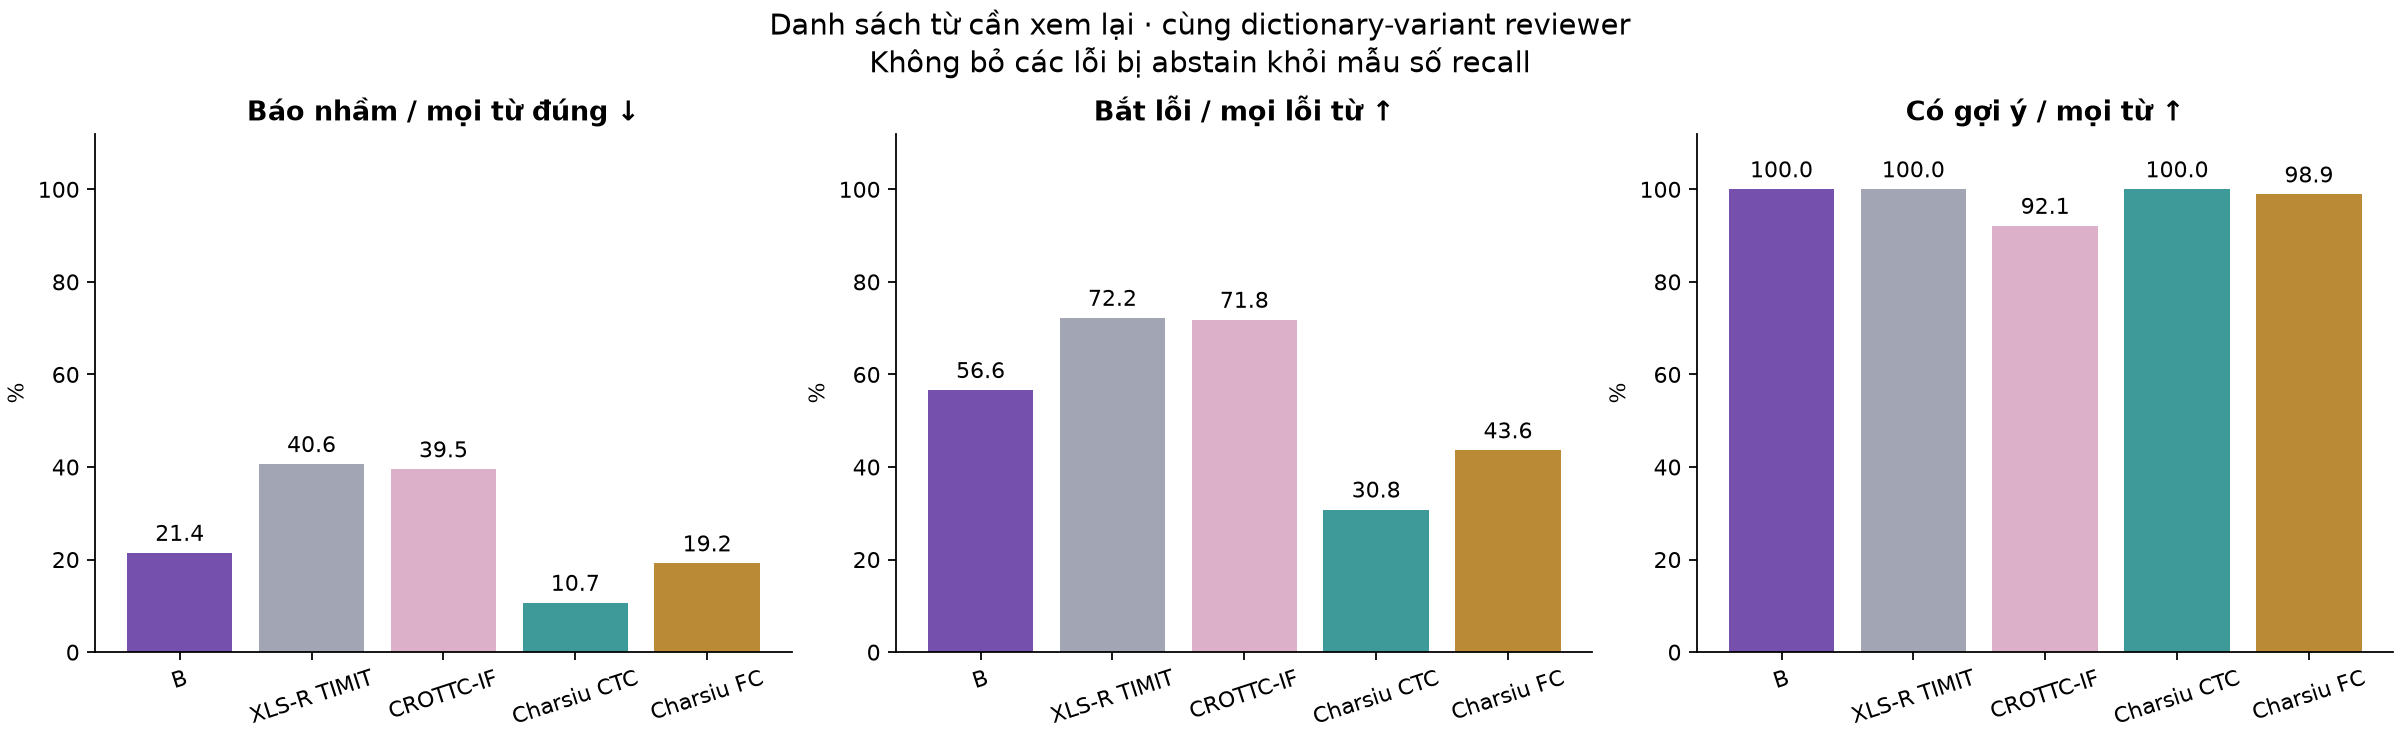

In [4]:
columns = ["model", "review_reference_words", "review_gold_error_words", "review_available_words", "review_false_positive_all_correct", "review_false_positive_rate_decided", "review_recall_all_errors", "review_recall_available_only", "review_coverage"]
display(models.loc[models.inventory == "research_full39", columns])
display(Image(filename=str(OUT / "word_review.png")))

## 4. Theo speaker và giọng Việt

Mỗi speaker chỉ có 20 audio. TLV là một speaker Việt; kết quả này không đại diện cho mọi người Việt nói tiếng Anh.

,speaker,model,cases,f1,per,review_recall_all_errors,review_false_positive_all_correct,review_coverage
15,TLV,cascade-B,20,0.712871,0.190332,0.751825,0.279412,1.000000
18,TLV,timit-xlsr-300m,20,0.621739,0.318731,0.832117,0.367647,1.000000
21,TLV,crottc-if,20,0.291904,0.945619,0.912409,0.573529,0.956098
24,TLV,charsiu-ctc,20,0.516971,0.317221,0.547445,0.117647,1.000000
27,TLV,charsiu-fc10ms,20,0.492823,0.367069,0.569343,0.205882,0.936585


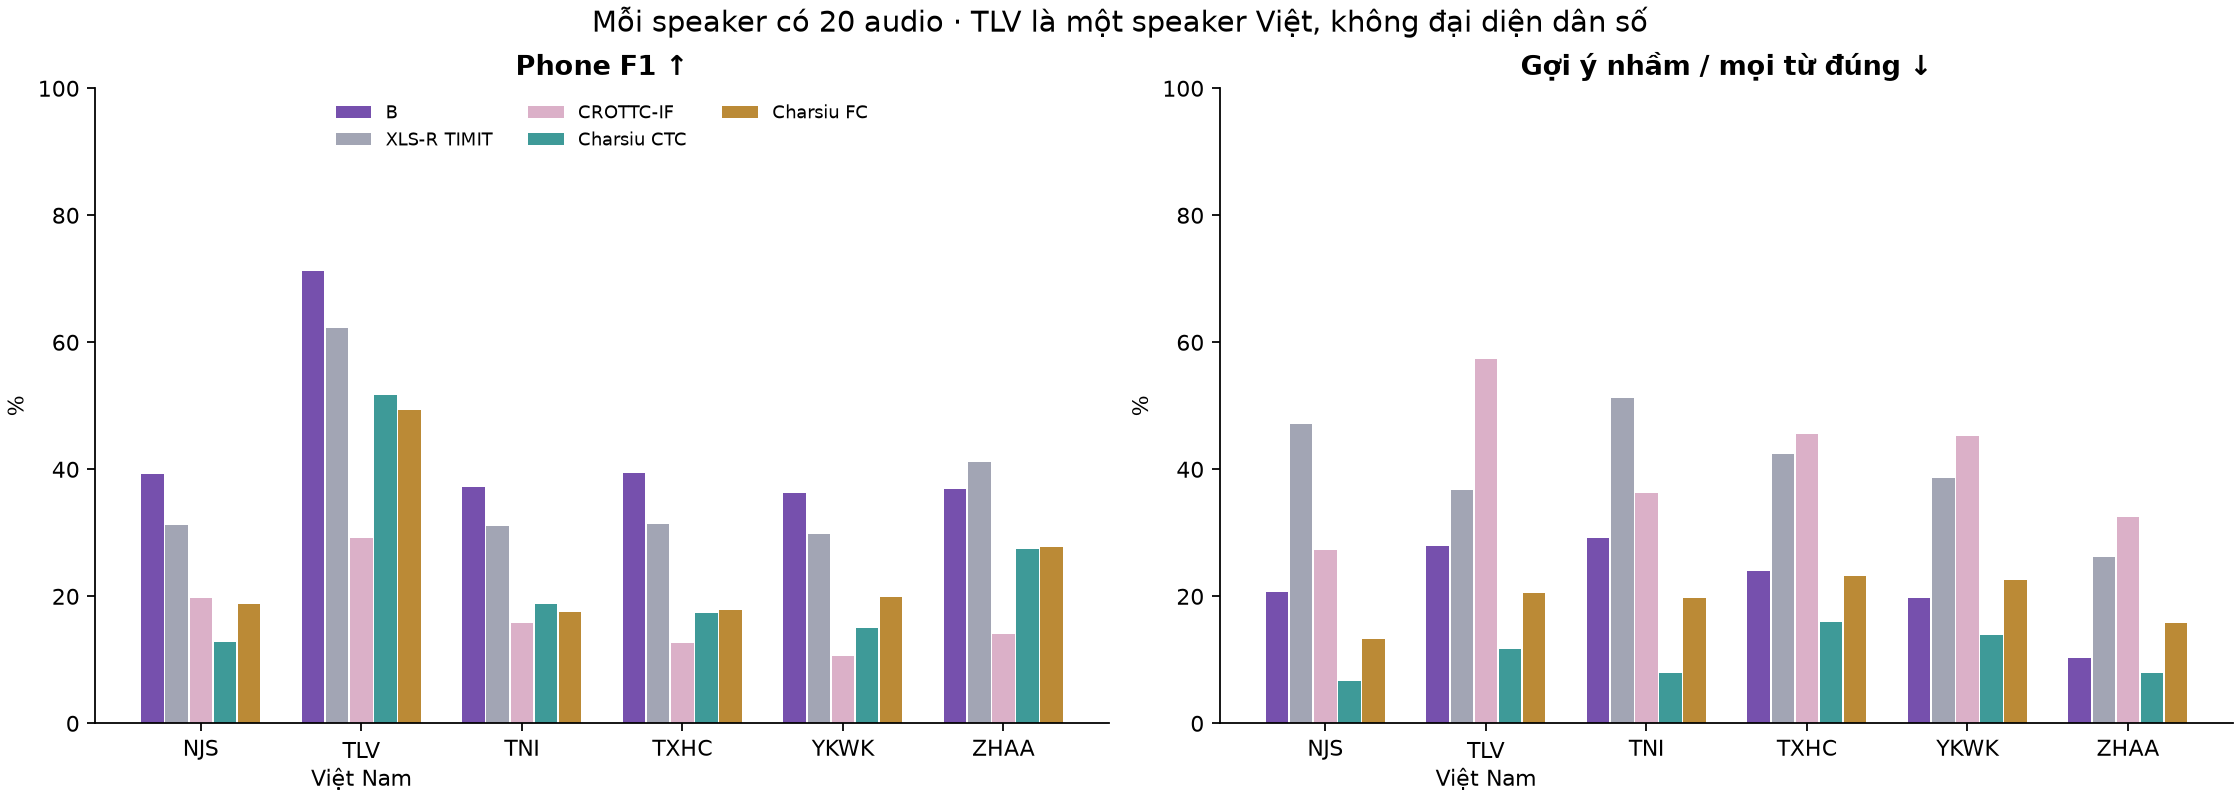

In [5]:
speaker = pd.DataFrame(report.model_rows(bundle, by_speaker=True))
display(speaker.loc[(speaker.speaker == "TLV") & (speaker.inventory == "research_original_inventory"), ["speaker", "model", "cases", "f1", "per", "review_recall_all_errors", "review_false_positive_all_correct", "review_coverage"]])
display(Image(filename=str(OUT / "by_speaker.png")))

## 5. Giữ B và thay policy quyết định

HJK/LXC dùng fit; PNV dùng audit; test 120 audio chỉ được đánh giá sau khi ngưỡng khóa. Cột eligible/failures phản ánh điều kiện đăng ký. Policy không đạt vẫn được giữ nguyên trong báo cáo; notebook không chọn lại ngưỡng hay tự đưa vào demo.

Risk của policy chỉ gắn cờ lỗi là tỷ lệ cờ sai; với hai ngưỡng, risk còn tính chấp nhận sai. Không dùng hai đại lượng này như hai grade hoàn toàn tương đương.

Ngưỡng đã khóa:


Điều kiện đạt:


,group,policy,eligible,false_positive_all_correct,recall_all_errors,coverage,precision,decided_words
0,fit,dictionary-variant-review,—,24.34%,62.68%,98.54%,60.31%,2775
1,fit,error-cutoff-f05,False,0.00%,0.00%,0.00%,—,0
2,fit,selective-two-threshold,False,2.77%,12.15%,28.52%,72.16%,803
3,heldout,dictionary-variant-review,—,12.75%,65.93%,99.23%,82.47%,1412
4,heldout,error-cutoff-f05,False,0.00%,0.00%,0.00%,—,0
5,heldout,selective-two-threshold,False,0.94%,10.62%,27.55%,91.14%,392
6,test,dictionary-variant-review,—,21.45%,56.62%,100.00%,63.35%,1165
7,test,error-cutoff-f05,False,0.00%,0.00%,0.00%,—,0
8,test,selective-two-threshold,False,2.70%,11.71%,28.15%,73.97%,328


Các tỷ lệ điều kiện chỉ tính trên phần có quyết định:


,group,policy,false_positive_rate_decided,false_negative_rate_decided,risk_on_decided
0,fit,dictionary-variant-review,24.61%,36.04%,28.83%
1,fit,error-cutoff-f05,—,—,—
2,fit,selective-two-threshold,7.59%,19.11%,9.84%
3,heldout,dictionary-variant-review,12.82%,33.38%,22.59%
4,heldout,error-cutoff-f05,—,—,—
5,heldout,selective-two-threshold,2.41%,28.71%,9.18%
6,test,dictionary-variant-review,21.45%,43.38%,30.13%
7,test,error-cutoff-f05,—,—,—
8,test,selective-two-threshold,7.66%,32.50%,13.72%


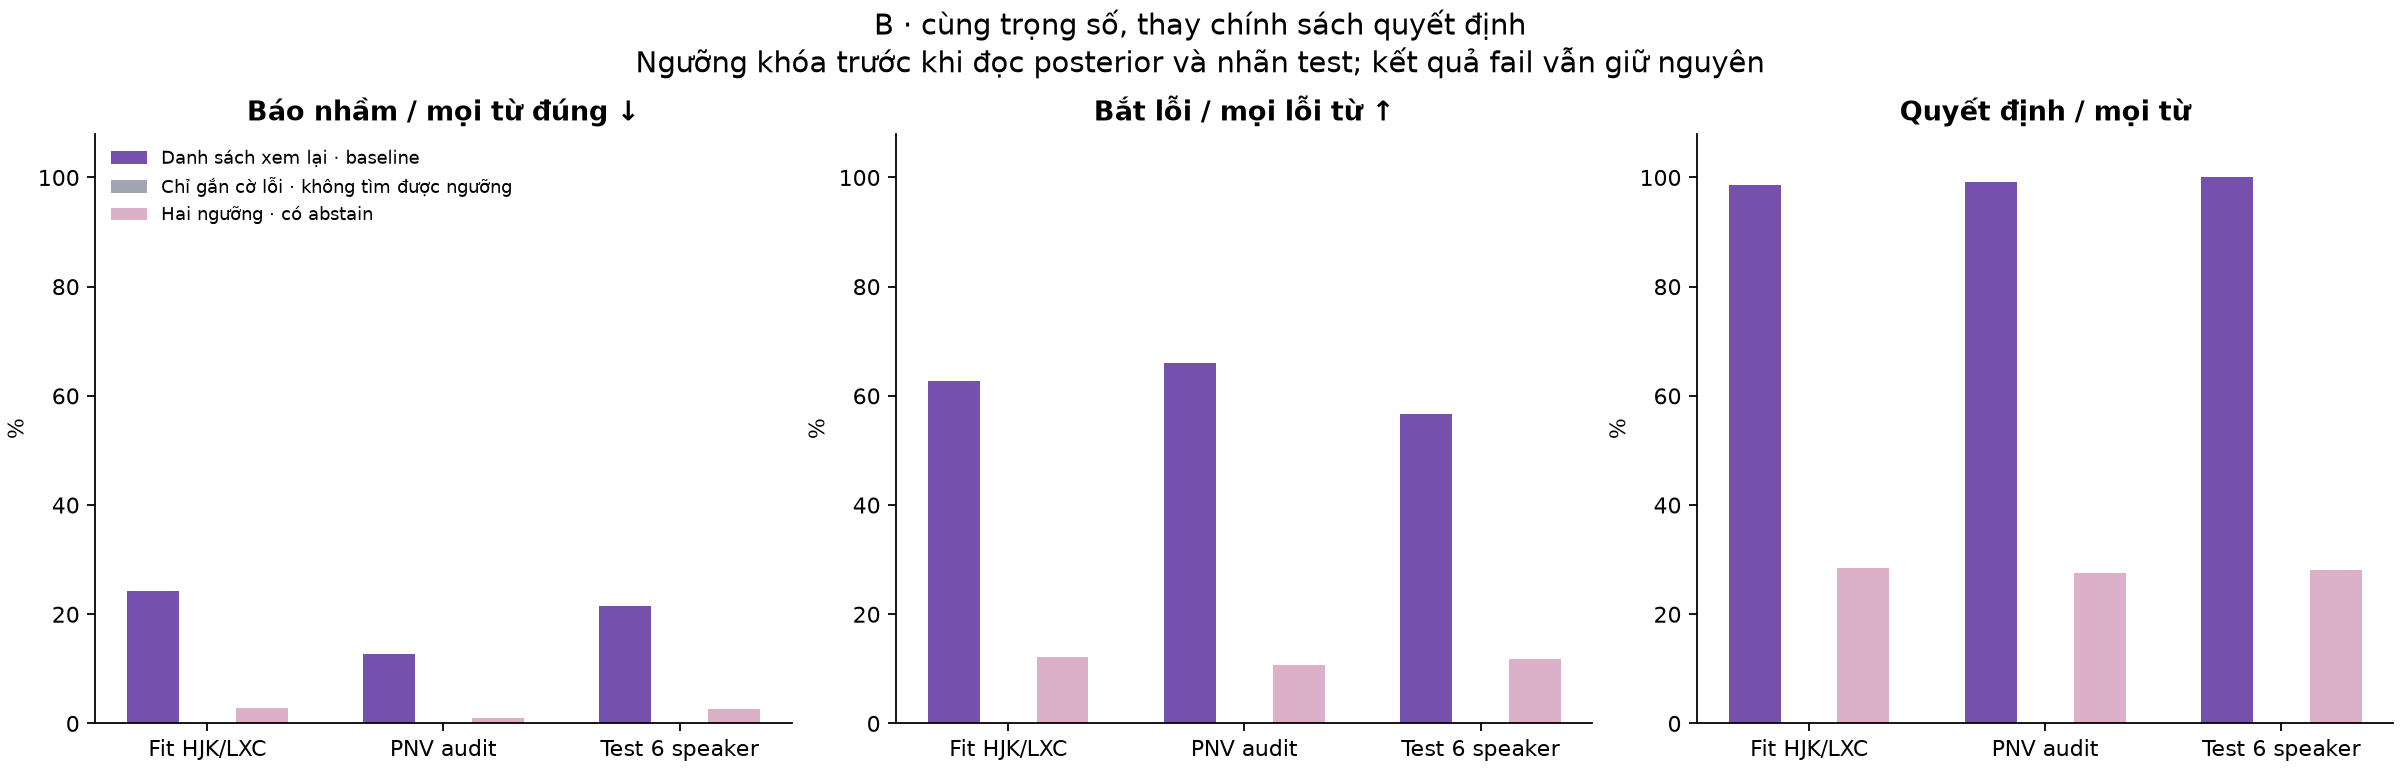

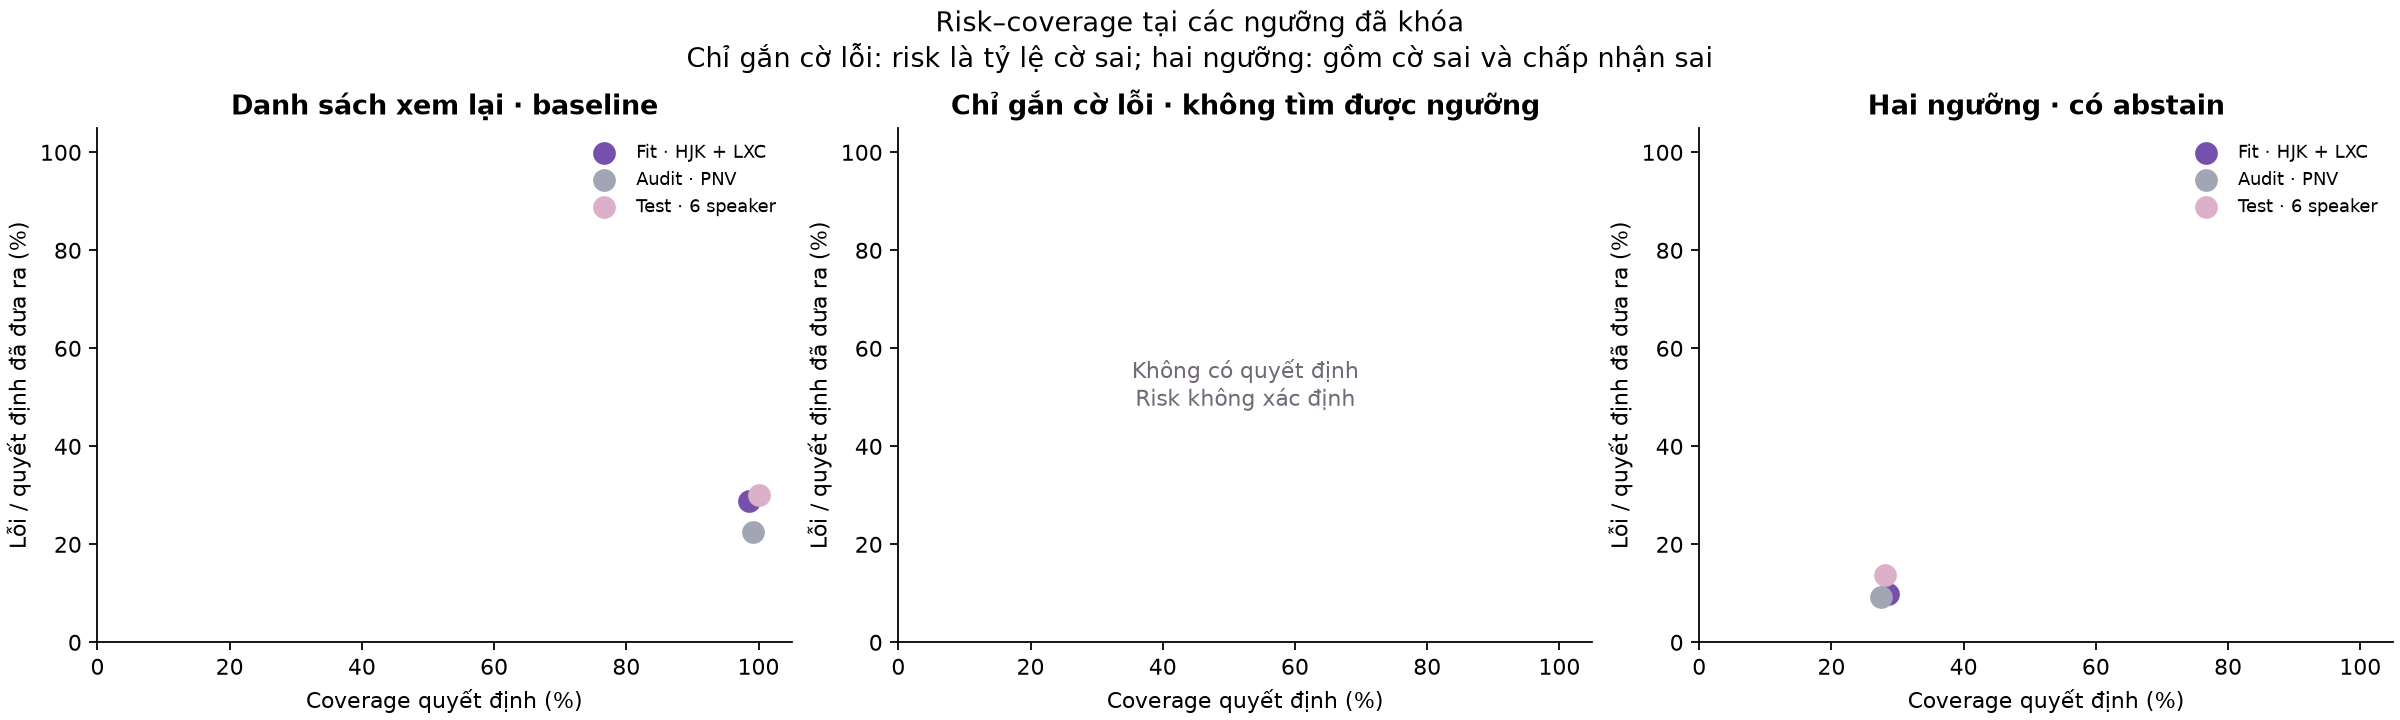

In [6]:
print("Ngưỡng đã khóa:")
display(HTML("<pre>" + report.esc(json.dumps(bundle["policy"].get("selected"), ensure_ascii=False, indent=2)) + "</pre>"))
print("Điều kiện đạt:")
display(HTML("<pre>" + report.esc(json.dumps(bundle["policy"].get("eligibility"), ensure_ascii=False, indent=2)) + "</pre>"))
policies = pd.DataFrame(report.policy_rows(bundle))
main_columns = ["group", "policy", "eligible", "false_positive_all_correct", "recall_all_errors", "coverage", "precision", "decided_words"]
rate_columns = ["false_positive_all_correct", "recall_all_errors", "coverage", "precision"]
display(policies[main_columns].style.format({key: "{:.2%}" for key in rate_columns}, na_rep="—"))
print("Các tỷ lệ điều kiện chỉ tính trên phần có quyết định:")
conditional_columns = ["group", "policy", "false_positive_rate_decided", "false_negative_rate_decided", "risk_on_decided"]
display(policies[conditional_columns].style.format({key: "{:.2%}" for key in conditional_columns[2:]}, na_rep="—"))
display(Image(filename=str(OUT / "locked_policy.png")))
display(Image(filename=str(OUT / "risk_coverage.png")))

## 6. Đầu ra trên audio của bạn

Ba audio phát triển có câu dự định đọc nhưng không có nhãn phoneme chuyên gia, nên không gán F1/PER. Bản HTML cho phép nghe audio, tìm câu và mở kết quả của cả năm model.

In [7]:
development = []
for case in bundle["manifest"]["cases"]:
    if case["group"] != "user_development":
        continue
    for model in report.MODELS:
        row = bundle["results"]["predictions"][model][case["id"]]
        development.append({"id": case["id"], "reference": case["reference_text"], "model": report.NAMES[model], "phones": " ".join(row["phonemes"]), "seconds": row["inference_sec"], "expert_score": "Không có nhãn chuyên gia"})
display(pd.DataFrame(development))
print("Báo cáo HTML:", OUT / "report.html")
for finding in report.findings(bundle):
    print("•", finding)

,id,reference,model,phones,seconds,expert_score
0,user-stella,Please call Stella. Ask her to bring these thi...,wav2vec2 B · local,B L IY K OW S EH L AH AA S HH AH T AH B R IH N...,0.250,Không có nhãn chuyên gia
1,user-stella,Please call Stella. Ask her to bring these thi...,XLS-R 300M · TIMIT,B L IY K AA L S T EH L ER AH S HH ER T UW B R ...,0.437,Không có nhãn chuyên gia
2,user-stella,Please call Stella. Ask her to bring these thi...,CROTTC-IF,S P B P L IY K OW AO OW AO W S EH S EH L AH AH...,135.875,Không có nhãn chuyên gia
3,user-stella,Please call Stella. Ask her to bring these thi...,Charsiu · CTC,B L IH K AO S T EH L OW AE S HH ER T UW B R IH...,0.250,Không có nhãn chuyên gia
4,user-stella,Please call Stella. Ask her to bring these thi...,Charsiu · FC 10 ms,B L UW K AO S T EH L ER AE S HH ER T UW B R IH...,0.453,Không có nhãn chuyên gia
5,user-road,End of the road for some players,wav2vec2 B · local,AH N D OW DH EH L OW D AH F AO R S AA M OW N P...,0.031,Không có nhãn chuyên gia
6,user-road,End of the road for some players,XLS-R 300M · TIMIT,AH N DH OW DH EY L OW DH AH F AA R S AA M UW M...,0.063,Không có nhãn chuyên gia
7,user-road,End of the road for some players,CROTTC-IF,AE AE AE N D N D OW AO OW AO OW DH Z DH EH EY ...,4.125,Không có nhãn chuyên gia
8,user-road,End of the road for some players,Charsiu · CTC,AH N D OW ER DH AH L AA D AH V F AO R S AH M A...,0.047,Không có nhãn chuyên gia
9,user-road,End of the road for some players,Charsiu · FC 10 ms,AE N D DH OW DH EH EY R L AO D AH V F AO R S A...,0.094,Không có nhãn chuyên gia


Báo cáo HTML: D:\NCC\MDD\data\generated\pronunciation-improvement-20261024\report.html
• Charsiu · CTC trên nhãn chuyên gia gốc: phone F1 29.54% (B 49.07%), PER 20.84% (B 16.78%); ở reviewer Full39, gợi ý nhầm / mọi từ đúng 10.65%, recall mọi lỗi từ 30.80% với coverage 100.00%.
• Charsiu · FC 10 ms trên nhãn chuyên gia gốc: phone F1 29.58% (B 49.07%), PER 23.72% (B 16.78%); ở reviewer Full39, gợi ý nhầm / mọi từ đúng 19.18%, recall mọi lỗi từ 43.60% với coverage 98.88%.
• Chỉ gắn cờ lỗi · không tìm được ngưỡng: không có ngưỡng đạt điều kiện trên fit; tất cả từ ở trạng thái chưa quyết định. FPR = 0 cùng recall = 0 và coverage = 0 không phải cải thiện phát âm.
• Hai ngưỡng · có abstain: chưa đạt điều kiện đăng ký; không tự đưa vào demo. Trên PNV, recall mọi lỗi 10.62%, coverage 27.55%, FNR phần quyết định 28.71%.  Chi tiết: ["false_negative_rate_decided"]
• Tradeoff của hai ngưỡng trên test: báo nhầm 151/704 (21.45%) → 19/704 (2.70%), nhưng recall mọi lỗi giảm 261/461 (56.62%) → 54/461 (

## Nguồn nghiên cứu và giới hạn

- [Charsiu, ICASSP 2022](https://arxiv.org/abs/2110.03876) · [code và checkpoint](https://github.com/lingjzhu/charsiu).
- [CTC-GOP, Interspeech 2024](https://www.isca-archive.org/interspeech_2024/cao24b_interspeech.html): hướng posterior scoring; policy nội bộ ở đây không phải tái lập công thức bài báo.
- [L2-ARCTIC](https://psi.engr.tamu.edu/l2-arctic-corpus/): nguồn audio và nhãn chuyên gia.
- [CROTTC-IF](https://arxiv.org/abs/2604.22133) · [checkpoint chính thức](https://huggingface.co/Haopeng/CROTTC-IF-l2-arctic): scoring/split khác nên không gọi kết quả local là tái lập điểm công bố.
- [SSL-FT-PRON](https://github.com/hy310/ssl_finetuning) có WavLM/HuBERT chấm bốn điểm toàn câu; PCC của tác vụ đó không tương đương F1 phát hiện lỗi âm.

Dữ liệu đã được quan sát ở benchmark trước. Test này không phải blind benchmark mới. PNV độc lập với việc chọn ngưỡng, nhưng từng tham gia validation chọn checkpoint B. Đọc cùng FPR, recall và coverage; không diễn giải abstain là phát âm đúng.